# Exploratory Data Analysis: Transit Improvement Projects

### Source: SEMCOG TIP map data

### Findings:
 - The greatest number of projects were started in 2023: **326**
 - Total project cost (across 856 projects): **$5,443,824,776.33**
 - Median project cost: **$1,223,056**
 - Mean project cost: **$6,359,608**
 - Biggest project: **I-94 E ramp, road reconstruction  ($356,070,000)**
 - Most projects are done at the State or County level (about equal)
 - The most expensive projects are done by MDOT or the State (and city/village projects are bigger than county)
 - Detroit, Ann Arbor and Troy are spending the most right now (led by Detroit, which has the most projects)


In [7]:
#imports
import pandas as pd
import geopandas as geo
import matplotlib.pyplot as plt

In [ ]:
#read data file
projects = geo.read_file('data/geo/tip_projects.geojson')
projects.head()

### Check out the file

<Axes: >

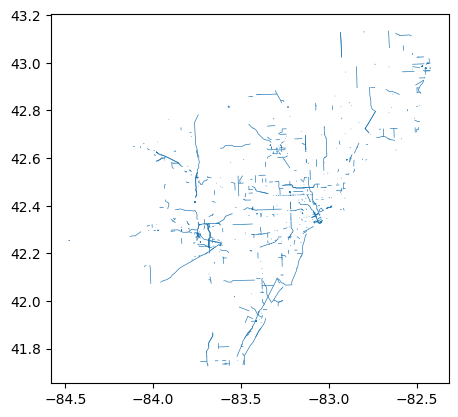

In [8]:
projects.plot()

In [9]:
#columns
projects.columns

Index(['phase', 'merge_src', 'rpt_wk_desc', 'conyear', 'rpt_rte_name',
       'otherph', 'jurisdiction', 'fac', 'tot_prj_co', 'ftpm_area',
       'jobnet_id', 'agn_name', 'tot_prj_lc', 'projtype', 'rpt_loc_desc',
       'tot_prj_st', 'SHAPE__Length', 'objectid', 'tot_prj_fe', 'SHAPE__Area',
       'geometry'],
      dtype='str')

In [10]:
#what phases are projects in?
projects['phase'].value_counts()

phase
CON         604
NI          179
CON, CON     20
PE           18
OPS          17
ROW           7
EPE           3
PES           3
PES, CON      2
ROW, CON      1
PE, PE        1
UTL           1
Name: count, dtype: int64

In [12]:
#when did the projects start?
projects['conyear'].value_counts()

conyear
2023    326
2024    235
2025    151
2026    126
2027     16
2029      2
Name: count, dtype: int64

In [13]:
#what about cost? - total
projects['tot_prj_co'].sum()

np.float64(5443824776.33)

In [52]:
#cost - average
projects['tot_prj_co'].mean()

np.float64(6359608.383563084)

In [15]:
#cost - max
projects['tot_prj_co'].max()

np.float64(356070000.0)

In [53]:
#what's the biggest project?
projects.sort_values(by='tot_prj_co', ascending=False).head(1)

,phase,merge_src,rpt_wk_desc,conyear,rpt_rte_name,otherph,jurisdiction,fac,tot_prj_co,ftpm_area,...,agn_name,tot_prj_lc,projtype,rpt_loc_desc,tot_prj_st,SHAPE__Length,objectid,tot_prj_fe,SHAPE__Area,geometry
782,CON,Hosted\TIP_Projects_FY_2023_to_2026\TIP_Projec...,Road Reconstruction,2025,French/I-94 E Ramp,NaN,MDOT,Wayne,356070000.0,Pavement,...,MDOT,8078338.0,Pavement,I-94 east of X01 82024 (Conrail RR) to west of...,56548367.0,21912.428534,783,291443295.0,1.185860e+07,"POLYGON ((-82.98853 42.39397, -82.9879 42.3944..."


### Where are projects happening?

In [20]:
#projects by jurisdiction - most projects are at the state level (highways)
projects['jurisdiction'].value_counts()

jurisdiction
State              280
County             236
Transit            157
City or Village    121
MDOT                28
Municipality        19
Region              13
Area Wide            2
Name: count, dtype: int64

In [26]:
#average cost of project by jurisdiction - interesting that city or village projects are more costly than county-level ones
projects[['jurisdiction', 'tot_prj_co', 'objectid']].groupby('jurisdiction').agg(
    {
        'objectid': 'count',
        'tot_prj_co': 'median'
    }
).reset_index().rename(columns={'objectid': 'count', 'tot_prj_co': 'median_cost'}).sort_values(by='median_cost', ascending=False)

,jurisdiction,count,median_cost
0,Area Wide,2,7975485.0
3,MDOT,28,7300717.5
6,State,280,1941271.0
1,City or Village,121,1159801.0
2,County,236,912310.0
4,Municipality,19,900000.0
7,Transit,157,520000.0
5,Region,13,350000.0


In [49]:
#which cities are spending the most?
city_proj = projects[projects['jurisdiction'] == 'City or Village']
city_proj[['agn_name', 'tot_prj_co', 'objectid']].groupby('agn_name').agg(
    {
        'objectid': 'count',
        'tot_prj_co': 'sum'
    }
).reset_index().rename(columns={'objectid': 'count', 'tot_prj_co': 'total_cost'}).sort_values(by='total_cost', ascending=False).head(10)

,agn_name,count,total_cost
7,Detroit,23,47445637.0
1,Ann Arbor,17,28019972.0
43,Troy,2,22658750.0
31,Pontiac,9,10955068.0
46,Ypsilanti,4,6688101.0
41,Sterling Heights,3,6642632.0
28,Novi,6,6553724.0
10,Farmington Hills,5,6335417.0
40,St. Clair Shores,3,5470795.0
37,Royal Oak,4,3825358.0
